![Original climate-globe illustration introducing Climate Pulse: a reproducible observatory; illustrative, not a data map](assets/atlas-splash.png)

# 21 · Climate Pulse: a reproducible observatory

**Guiding question:** What does a near-real-time climate dashboard actually measure?

**Data:** Real C3S/ECMWF ERA5 Climate Pulse CSV snapshots retrieved 2026-11-20; CC BY 4.0  
**Time:** 20–35 minutes · **Prerequisites:** basic Python; run cells from top to bottom.  
**Author:** JupyterLite-C3S-Atlas contributors (AI assisted) · **Created/updated:** 2026-11-20  
**Inputs:** bundled reference files and/or seeded examples specified below. **Outputs:** tables, figures, and any explicitly named local exports; source data are not modified.  
**Runtime:** Python/Pyodide; NumPy, pandas, Matplotlib, Plotly; versions and tests are recorded in the validation report.  
**Change log:** initial educational chapter. **Contact:** [repository issues](https://github.com/jltobias/JupyterLite-C3S-Atlas/issues).

[Open in JupyterLite Lab](https://jltobias.github.io/JupyterLite-C3S-Atlas/lite/lab/index.html?path=21-climate-pulse-observatory.ipynb) · [Official Atlas](https://atlas.climate.copernicus.eu/)


## Read the evidence

A monitoring result needs a timestamp as well as a value. Climate Pulse
        provides a recent view of ERA5 reanalysis; this book preserves a **fixed snapshot**
        so a class can reproduce the same calculation next month. Reanalysis combines
        observations and a model. It is neither a single thermometer nor a forecast.

        Start a monitoring record with quantity, region, time support, baseline, source
        version, and retrieval date. The bundled monthly products end in October 2026;
        the daily Niño 3.4 file extends to 18 November. Check these boundaries in code.
        Some recent values can be revised. Read the `status` field instead of assuming
        the newest sample is final.

        **A metadata reading exercise:** the daily SST header has a generic “daily means”
        description but a specific note stating **12 UTC SST**. Preserve both statements,
        follow the specific note for this exercise, and seek producer clarification before
        treating daily and monthly exports as identical aggregations. This is why provenance
        must include the original header, not just a convenient column name.

## Start the browser lab

Run this setup cell once. First load needs internet for the Python runtime and packages. The remaining lesson uses bundled data. If a 3D view is unavailable, use the 2D/table alternative. Download your edited notebook before clearing browser storage.

In [1]:
# Install only in the browser kernel; desktop dependencies come from requirements.txt.
import sys
if sys.platform == "emscripten":
    import piplite
    await piplite.install(["numpy", "pandas", "matplotlib", "plotly==6.5.0"])

import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plotly.graph_objects as go
from IPython.display import display
from atlas_helpers import (
    DATA, SYNTHETIC, COLORS, show, monthly_demo, anomalies, regular_grid,
    area_mean, coastlines, map_figure, globe_figure, warming_levels, load_monthly_csv,
)
print("Ready. Browser edits live in this browser; download work you want to keep.")


Ready. Browser edits live in this browser; download work you want to keep.


## Audit the evidence

In [2]:
from pulse_helpers import (
    load_pulse, complete_months, rank_same_month, region_rings, region_geojson,
    region_map, region_globe, REGIONS, ANOM, REL, CREDIT, BASE,
)
import hashlib
manifest = json.loads((DATA / "pulse/manifest.json").read_text(encoding="utf-8"))
records = []
for record in manifest:
    path = DATA / record["file"]
    assert hashlib.sha256(path.read_bytes()).hexdigest() == record["sha256"]
    frame = pd.read_csv(path, comment="#")
    records.append({"file": path.name, "rows": len(frame), "first": frame.date.min(),
                    "last": frame.date.max(), "licence": record["licence"]})
display(pd.DataFrame(records))

,file,rows,first,last,licence
0,timeseries_era5_sst_monthly_nino12.csv,574,1979-01-01,2026-10-01,CC-BY-4.0
1,timeseries_era5_sst_monthly_nino3.csv,574,1979-01-01,2026-10-01,CC-BY-4.0
2,timeseries_era5_sst_monthly_nino34.csv,574,1979-01-01,2026-10-01,CC-BY-4.0
3,timeseries_era5_sst_monthly_nino4.csv,574,1979-01-01,2026-10-01,CC-BY-4.0
4,timeseries_era5_sst_monthly_60S-60N_ocean.csv,574,1979-01-01,2026-10-01,CC-BY-4.0
5,timeseries_era5_t2m_monthly_global.csv,1042,1940-01-01,2026-10-01,CC-BY-4.0
6,timeseries_era5_sst_daily_nino34.csv,17489,1979-01-01,2026-11-18,CC-BY-4.0


## Locate the newest daily point in its recent context

,date,sst,anom_1991_2020,rnino_anom_1991_2020,status
17485,2026-11-15,30.0795,3.3472,2.5365,FINAL
17486,2026-11-16,30.0398,3.3101,2.4818,FINAL
17487,2026-11-17,30.0322,3.3054,2.4959,FINAL
17488,2026-11-18,30.0896,3.3659,2.5701,FINAL


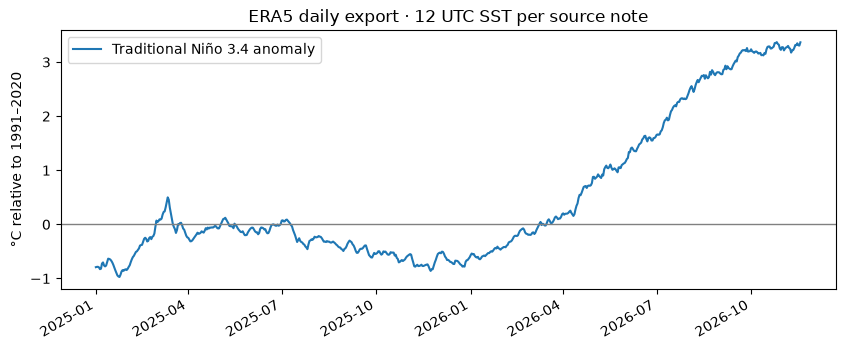

In [3]:
daily = load_pulse(aggregation="daily")
display(daily.tail(4)[["date", "sst", ANOM, REL, "status"]])
recent = daily[daily.date >= "2025-01-01"]
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.plot(recent.date, recent[ANOM], label="Traditional Niño 3.4 anomaly")
ax.axhline(0, color="gray", lw=1)
ax.set(title="ERA5 daily export · 12 UTC SST per source note", ylabel="°C relative to 1991–2020")
ax.legend(); fig.autofmt_xdate(); plt.show()

## Open the same selection in official Climate Pulse

In [4]:
from app_helpers import pulse_link
from IPython.display import Markdown
url = pulse_link(region="nino34", aggregation="daily", date="2026-11-18", quantity="anomaly")
display(Markdown(f"[Open this selection in the official Climate Pulse app]({url})"))
print("Check the displayed region, date, aggregation, quantity, and baseline after opening.")
print("The official app may update or revise its data. The notebook keeps its dated snapshot.")
print("For a gridded map, use Pulse’s map view and probe; a relative Niño index is a regional time series.")

[Open this selection in the official Climate Pulse app](https://pulse.climate.copernicus.eu/?variable=sst&region=nino-3-4&series=anomaly&map=anomaly&aggregation=daily&date=2026-11-18)

Check the displayed region, date, aggregation, quantity, and baseline after opening.
The official app may update or revise its data. The notebook keeps its dated snapshot.
For a gridded map, use Pulse’s map view and probe; a relative Niño index is a regional time series.


## Try it and explain

Read one raw header in data/pulse. Identify a claim the numerical columns alone could not support.

**Interpretation check:** A date/value pair does not reveal spatial averaging, baseline, preliminary status, or the time-of-day convention. Those are part of the evidence.

## Transfer to the official tools

Open Climate Pulse, note its newest timestamp, and compare it with this archived snapshot. Save the official share link and export metadata; a changing live link is not an immutable data version.

Record the selections, source version, units, periods, and uncertainty legend. These independent lessons do not duplicate every production workflow in the official tools.

## Sources and credit

- [C3S Atlas dataset and DOI](https://doi.org/10.24381/cds.h35hb680)
- [CSIC / Predictia Atlas user guide](https://confluence.ecmwf.int/spaces/CKB/pages/394237545/Copernicus+Interactive+Climate+Atlas+User+Guide)
- [Official C3S Atlas User Tools and contributors](https://ecmwf-projects.github.io/c3s-atlas/)
- [C3S Climate Pulse 2.0 announcement (10 November 2026)](https://climate.copernicus.eu/new-version-climate-pulse-provides-new-monitoring-el-nino-conditions)
- [Climate Pulse FAQs and methodology](https://pulse.climate.copernicus.eu/faqs)
- [Climate Pulse credits and citations](https://pulse.climate.copernicus.eu/credits)
- [ERA5 monthly data: C3S/ECMWF and ERA5 contributors](https://doi.org/10.24381/cds.f17050d7)
- [Hersbach et al. (2020): The ERA5 global reanalysis](https://doi.org/10.1002/qj.3803)
- [Official Climate Pulse application](https://pulse.climate.copernicus.eu/)

Original teaching text and code; original AI-generated splash illustration. Real reference files retain their source licences. Synthetic examples are not Copernicus measurements. See [credits](credits.md) and [data guide](data-guide.md).

**Continue:** [Four windows on the tropical Pacific](22-pacific-regions.ipynb)